# 06 · CP vs MILP — the decision

Constraint programming and mixed-integer programming overlap. We model the **same** problems (bin packing, timetabling) in both CP-SAT and MILP (PuLP + CBC) and compare modelling effort and solve behaviour, so the guidance rests on demonstration, not assertion.

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook runs from repo root or notebooks/.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

%matplotlib inline
import matplotlib.pyplot as plt

from src.persistence import save_figure, save_json

print("figures ->", save_figure.__module__, "| ready")

figures -> src.persistence | ready


In [2]:
from src.datasets import instances
from src.evaluation.cp_vs_milp import compare_bin_packing, compare_timetabling

bin_packing = compare_bin_packing(instances.small_bin_packing(), time_limit=10.0)
timetabling = compare_timetabling(instances.small_timetabling(), time_limit=10.0)
comparisons = [bin_packing, timetabling]
for c in comparisons:
    print(f"{c.problem:12} | CP {c.cp_status:8} obj={c.cp_objective} {c.cp_time:6.3f}s"
          f"  | MILP {c.milp_status:8} obj={c.milp_objective} {c.milp_time:6.3f}s"
          f"  | agree={c.objectives_agree}")
save_json("06_cp_vs_milp", comparisons)

bin_packing  | CP OPTIMAL  obj=3.0  0.008s  | MILP Optimal  obj=3.0  0.012s  | agree=True
timetabling  | CP OPTIMAL  obj=0.0  0.002s  | MILP Optimal  obj=0.0  0.004s  | agree=True


PosixPath('/workspaces/constraint_programming_101/outputs/data/06_cp_vs_milp.json')

## Solve time, side by side

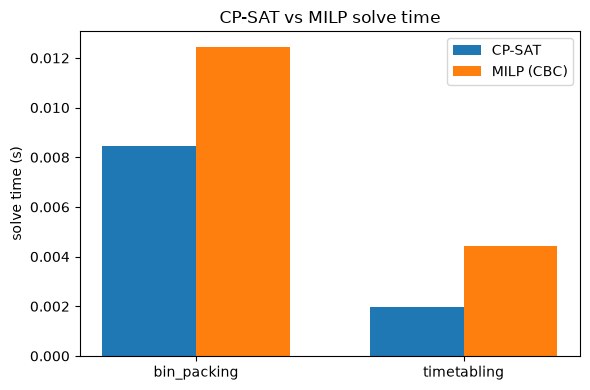

In [3]:
import numpy as np

labels = [c.problem for c in comparisons]
xpos = np.arange(len(labels))
width = 0.35
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(xpos - width / 2, [c.cp_time for c in comparisons], width, label="CP-SAT")
ax.bar(xpos + width / 2, [c.milp_time for c in comparisons], width, label="MILP (CBC)")
ax.set_xticks(xpos)
ax.set_xticklabels(labels)
ax.set_ylabel("solve time (s)")
ax.set_title("CP-SAT vs MILP solve time")
ax.legend()
fig.tight_layout()
save_figure("06_cp_vs_milp_times", fig)
plt.show()

## How to choose

**Reach for constraint programming** on scheduling, sequencing, rostering, timetabling, and heavily logical or feasibility-driven problems with discrete decisions — where rules like all-different, no-overlap, and exactly-*k* are the model.

**Reach for MILP** when the problem has strong linear structure, continuous variables, or an objective that is a clean weighted sum.

They overlap, and both solvers here are open-source (CP-SAT and CBC), so **trying both is cheap and informative**.

*Cross-links:* see `optimization_101` for the LP/MILP side and `routing_arena` for the OR-Tools routing toolkit; together they map the optimisation landscape.